# Comparing Evapotranspiration Between Two Areas with MODIS (MOD16A2)

Evapotranspiration (ET) is the water that leaves the land as evaporation from soil and water plus transpiration from
plants. In this notebook I compare ET between two areas side by side using the MODIS MOD16A2 product
(`MODIS/061/MOD16A2`, 500 m, one value every 8 days), the same data as my original Earth Engine script.

As an example I compare two neighbouring areas in California's San Joaquin Valley that get about the same, very
little, rain:

- **Irrigated farmland** on the west side of the valley (around Five Points and Huron), and
- **Rain-fed rangeland** in the Diablo Range hills just to the west.

The difference between the two is mostly water that was brought in by irrigation. You can swap in any two (or more)
areas you want to compare in Section 2.

**What I added to my original script**

- Removed MODIS "fill" values (water, urban and barren pixels have no ET in this product and are stored as large codes).
- Besides the 2023 chart from my original script, I added monthly and yearly totals, the average seasonal cycle,
  and the long-term record back to 2001, so a single year can be seen in context.
- A map of yearly ET with the two areas outlined.

## 1. Setup

Earth Engine results are saved to `outputs/modis_et/` year by year, so **Restart & Run All** after a restart is quick.

In [1]:
import os
import ee
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy import stats
ee.Initialize(project="XXXXX")   # <-- replace with your Earth Engine project ID
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "font.size": 11})

C:\Users\moham\anaconda3\Lib\site-packages\google\api_core\_python_version_support.py:254: FutureWarning: You are using a Python version (3.11.18) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


## 2. The areas I compare and other settings

In [2]:
# Folders where I save tables and figures
FIG_DIR, OUT_DIR = "figures/modis_et", "outputs/modis_et"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# The areas to compare, as [west, south, east, north]. Replace them with your own (two or more).
# Colours follow my original chart: the first area in black, the second in red.
REGIONS = {
    "Irrigated farmland (west San Joaquin Valley)": [-120.35, 36.25, -120.05, 36.55],
    "Rain-fed rangeland (Diablo Range)":           [-120.80, 36.25, -120.50, 36.55],
}
COLORS = ["black", "red", "#2171b5", "#31a354"]

FOCUS_YEAR = 2023                  # the year shown in my original chart
START_YEAR, END_YEAR = 2001, 2024  # the long-term record
SCALE = 500                        # MODIS pixel size (m), as in my original script

regions_fc = ee.FeatureCollection([ee.Feature(ee.Geometry.Rectangle(b), {"name": n}) for n, b in REGIONS.items()])
names = list(REGIONS)

## 3. MODIS ET every 8 days

The `ET` band is stored in units of 0.1 kg/m² per 8 days, so I multiply by 0.1 to get **mm per 8 days**
(1 kg of water spread over 1 m² is 1 mm). Values above 3270 before scaling are fill codes, not ET, so I drop them.

In [3]:
def to_mm(img):
    et = img.select("ET")
    return (et.updateMask(et.lte(3270)).multiply(0.1).rename("MODIS_ET")
              .copyProperties(img, ["system:time_start"]))

et = ee.ImageCollection("MODIS/061/MOD16A2").map(to_mm)

def region_means(img):
    # Average ET in each area for one 8-day period, plus the share of each area that has an ET value
    layers = ee.Image.cat(img, img.mask().rename("valid"))
    stats_fc = layers.reduceRegions(collection=regions_fc, reducer=ee.Reducer.mean(), scale=SCALE)
    date = img.date().format("YYYY-MM-dd")
    return stats_fc.map(lambda f: ee.Feature(None, {"date": date, "region": f.get("name"),
                                                     "et_mm": f.get("MODIS_ET"), "valid": f.get("valid")}))

ET_CSV = f"{OUT_DIR}/et_8day_by_region.csv"
saved = pd.read_csv(ET_CSV) if os.path.exists(ET_CSV) else pd.DataFrame()
# If the areas were changed, start again
if len(saved) and set(saved["region"]) != set(names):
    print("The areas changed since the last run - recomputing.")
    saved = pd.DataFrame()
done_years = set(pd.to_datetime(saved["date"]).dt.year) if len(saved) else set()

for year in range(START_YEAR, END_YEAR + 1):
    if year in done_years:
        continue
    fc = et.filterDate(f"{year}-01-01", f"{year + 1}-01-01").map(region_means).flatten()
    rows = [f["properties"] for f in fc.getInfo()["features"]]
    saved = pd.concat([saved, pd.DataFrame(rows)], ignore_index=True)
    saved.to_csv(ET_CSV, index=False)
    print(f"{year}: {len(rows) // len(names)} periods")

eight_day = (saved.assign(date=lambda d: pd.to_datetime(d["date"]))
                  .pivot_table(index="date", columns="region", values="et_mm")[names])
print(f"{eight_day.index.min():%Y-%m-%d} to {eight_day.index.max():%Y-%m-%d}")
print("Share of each area with ET values:", saved.groupby("region")["valid"].mean().round(2).to_dict())

2001: 0 periods
2002: 0 periods
2003: 0 periods
2004: 0 periods
2005: 0 periods
2006: 0 periods
2007: 0 periods
2008: 0 periods
2009: 0 periods
2010: 0 periods
2011: 0 periods
2012: 0 periods
2013: 0 periods
2014: 0 periods
2015: 0 periods
2016: 0 periods
2017: 0 periods
2018: 0 periods
2019: 0 periods
2020: 0 periods
2021: 46 periods
2022: 45 periods
2023: 46 periods
2024: 46 periods
2021-01-01 to 2024-12-26
Share of each area with ET values: {'Irrigated farmland (west San Joaquin Valley)': 0.99, 'Rain-fed rangeland (Diablo Range)': 1.0}


## 4. My original chart: the focus year

The same comparison as my original script (an area chart, first area in black, second in red), for `FOCUS_YEAR`.

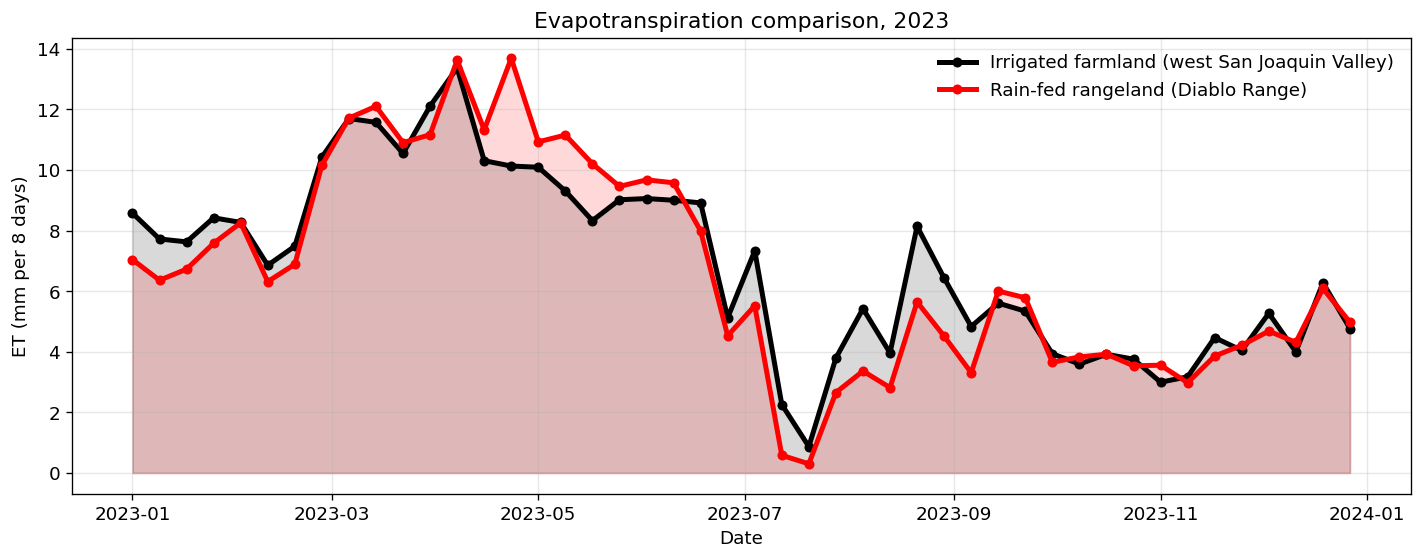

In [4]:
focus = eight_day.loc[str(FOCUS_YEAR)]
fig, ax = plt.subplots(figsize=(12, 4.8))
for name, color in zip(names, COLORS):
    ax.fill_between(focus.index, focus[name], color=color, alpha=0.15)
    ax.plot(focus.index, focus[name], "o-", color=color, lw=3, ms=5, label=name)
ax.set(xlabel="Date", ylabel="ET (mm per 8 days)", title=f"Evapotranspiration comparison, {FOCUS_YEAR}")
ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/01_et_comparison_{FOCUS_YEAR}.png"); plt.show()

## 5. Monthly and yearly totals

In [5]:
# Spread each 8-day total evenly over its days, then add up by month and year.
# This avoids counting a period twice when it crosses the end of a month.
def daily_from_8day(series):
    out = []
    for start, value in series.dropna().items():
        days = pd.date_range(start, periods=8, freq="D")
        days = days[days.year == start.year]           # the last period of the year is only 5-6 days long
        out.append(pd.Series(value / len(days), index=days))
    return pd.concat(out)

daily = pd.DataFrame({name: daily_from_8day(eight_day[name]) for name in names})
monthly = daily.resample("MS").sum(min_count=20)
annual = daily.resample("YS").sum(min_count=300)
annual.index = annual.index.year

monthly.round(1).to_csv(f"{OUT_DIR}/et_monthly_by_region.csv")
annual.round(1).to_csv(f"{OUT_DIR}/et_annual_by_region.csv")

years = annual.index.to_numpy(dtype=float)
rows = {}
for name in names:
    y = annual[name].to_numpy(dtype=float)
    ok = np.isfinite(y)
    slope = stats.theilslopes(y[ok], years[ok])[0]
    tau, p = stats.kendalltau(years[ok], y[ok])
    clim = monthly[name].groupby(monthly.index.month).mean()
    rows[name] = {
        f"ET in {FOCUS_YEAR} (mm)": annual.loc[FOCUS_YEAR, name],
        f"Average yearly ET {START_YEAR}–{END_YEAR} (mm)": np.nanmean(y),
        "Highest year": f"{int(annual[name].idxmax())} ({annual[name].max():.0f} mm)",
        "Lowest year": f"{int(annual[name].idxmin())} ({annual[name].min():.0f} mm)",
        "Peak month (on average)": pd.Timestamp(2001, int(clim.idxmax()), 1).strftime("%B"),
        "Trend (mm/decade, Theil–Sen)": 10 * slope,
        "Mann–Kendall p-value": p,
    }
summary = pd.DataFrame(rows)
if len(names) >= 2:
    gap = annual[names[0]] - annual[names[1]]
    print(f"On average, '{names[0]}' loses {gap.mean():.0f} mm more water to ET per year than '{names[1]}'.")
summary.to_csv(f"{OUT_DIR}/et_summary.csv")
summary

On average, 'Irrigated farmland (west San Joaquin Valley)' loses 27 mm more water to ET per year than 'Rain-fed rangeland (Diablo Range)'.


,Irrigated farmland (west San Joaquin Valley),Rain-fed rangeland (Diablo Range)
ET in 2023 (mm),318.132368,307.455762
Average yearly ET 2001–2024 (mm),268.064651,241.324766
Highest year,2023 (318 mm),2023 (307 mm)
Lowest year,2022 (232 mm),2022 (189 mm)
Peak month (on average),March,April
"Trend (mm/decade, Theil–Sen)",221.365949,343.34988
Mann–Kendall p-value,0.75,0.75


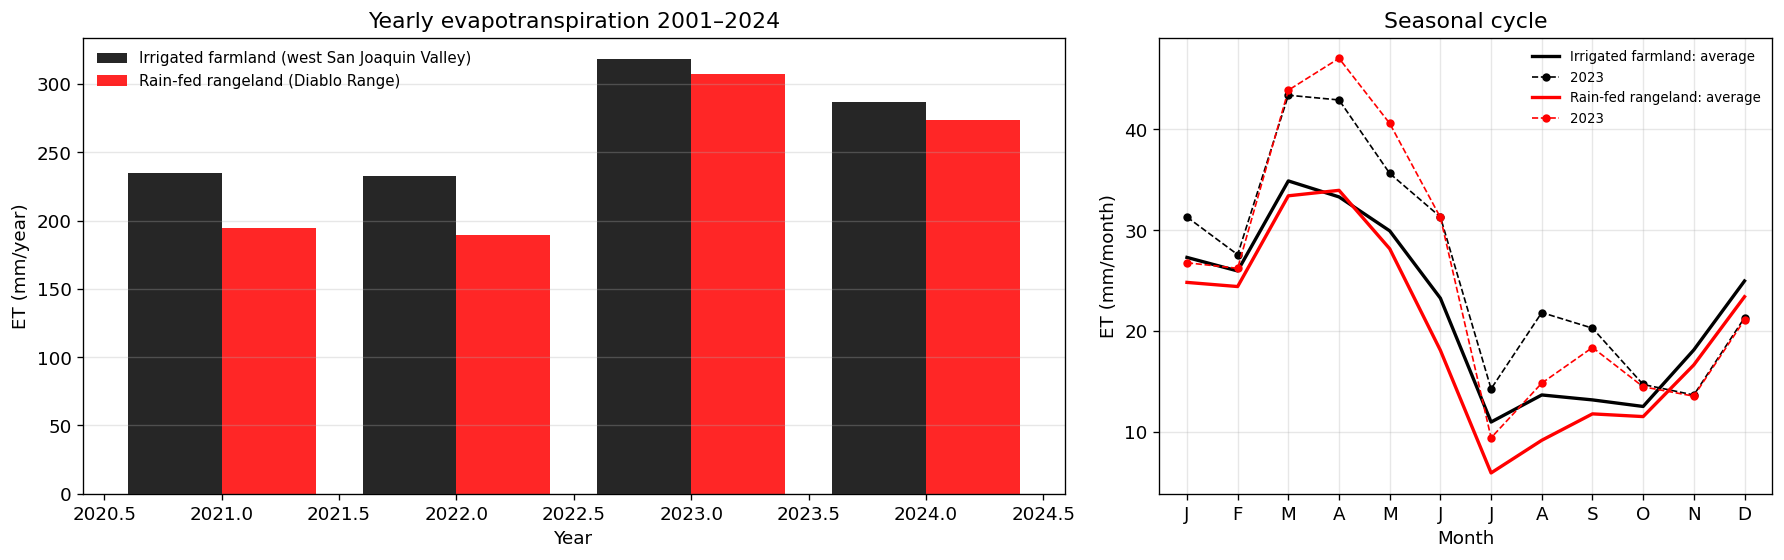

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})

# Yearly totals over the whole record
w = 0.8 / len(names)
for k, (name, color) in enumerate(zip(names, COLORS)):
    ax1.bar(annual.index + (k - (len(names) - 1) / 2) * w, annual[name], w, color=color, alpha=0.85, label=name)
ax1.set(xlabel="Year", ylabel="ET (mm/year)", title=f"Yearly evapotranspiration {START_YEAR}–{END_YEAR}")
ax1.legend(frameon=False, fontsize=9); ax1.grid(axis="y", alpha=0.3)

# Average seasonal cycle, with the focus year on top
for name, color in zip(names, COLORS):
    clim = monthly[name].groupby(monthly.index.month).mean()
    focus_m = monthly.loc[str(FOCUS_YEAR), name]
    ax2.plot(clim.index, clim.values, "-", color=color, lw=2, label=f"{name.split(' (')[0]}: average")
    ax2.plot(focus_m.index.month, focus_m.values, "o--", color=color, lw=1, ms=4, label=f"{FOCUS_YEAR}")
ax2.set(xticks=range(1, 13), xticklabels=list("JFMAMJJASOND"), xlabel="Month", ylabel="ET (mm/month)",
        title="Seasonal cycle")
ax2.legend(frameon=False, fontsize=8); ax2.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/02_et_yearly_and_seasonal.png"); plt.show()

## 6. Map of yearly ET with the two areas

Total ET for `FOCUS_YEAR` on the MODIS grid, downloaded as values so the map has a real colour scale.
Grey areas have no MODIS ET (water, towns, bare ground).

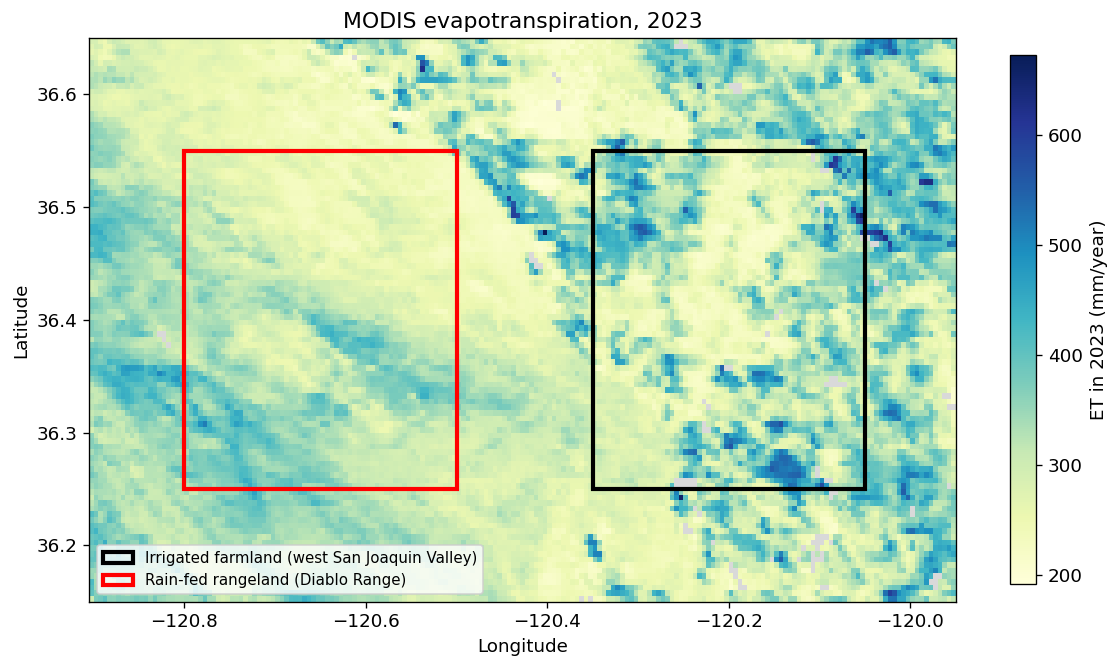

In [7]:
GRID_NPZ = f"{OUT_DIR}/et_map_{FOCUS_YEAR}.npz"
all_boxes = np.array(list(REGIONS.values()))
pad = 0.1
view_box = [all_boxes[:, 0].min() - pad, all_boxes[:, 1].min() - pad, all_boxes[:, 2].max() + pad, all_boxes[:, 3].max() + pad]
view = ee.Geometry.Rectangle(view_box)

if os.path.exists(GRID_NPZ):
    grid = dict(np.load(GRID_NPZ))
else:
    total = et.filterDate(f"{FOCUS_YEAR}-01-01", f"{FOCUS_YEAR + 1}-01-01").sum().rename("et_year")
    res = 0.005   # degrees, about 500 m
    stack = ee.Image.cat(total, ee.Image.pixelLonLat()).reproject(
        crs="EPSG:4326", crsTransform=[res, 0, view_box[0], 0, -res, view_box[3]])
    props = stack.sampleRectangle(region=view, defaultValue=-1).getInfo()["properties"]
    grid = {k: np.array(v, dtype=float) for k, v in props.items()}
    np.savez(GRID_NPZ, **grid)

data = np.ma.masked_less_equal(grid["et_year"], 0)
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_facecolor("#d9d9d9")
pm = ax.pcolormesh(grid["longitude"], grid["latitude"], data, cmap="YlGnBu", shading="nearest")
for (name, b), color in zip(REGIONS.items(), COLORS):
    ax.add_patch(mpatches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec=color, lw=2.5, label=name))
fig.colorbar(pm, ax=ax, label=f"ET in {FOCUS_YEAR} (mm/year)", shrink=0.8)
ax.set(xlabel="Longitude", ylabel="Latitude", title=f"MODIS evapotranspiration, {FOCUS_YEAR}")
ax.set_aspect(1 / np.cos(np.deg2rad(np.mean(view_box[1::2]))))
ax.legend(loc="lower left", fontsize=9)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/03_et_map_{FOCUS_YEAR}.png"); plt.show()

## 7. Notes

- **Data:** Running, S., Mu, Q., Zhao, M. (2021). MODIS/Terra Net Evapotranspiration 8-Day L4 Global 500 m (MOD16A2 v6.1).
- MOD16 estimates ET from weather data and how green the land looks; it does not know about irrigation directly. Studies
  have found it tends to **underestimate ET over irrigated fields** in dry regions, so the real difference between the
  two areas is probably larger than shown here.
- Pixels classed as water, urban or barren have no ET in this product. The "share with ET values" printed in Section 3
  tells you how much of each area is actually covered.
- The last 8-day period of each year is only 5–6 days long; I spread every period over its own days before adding up
  months and years, so nothing is counted twice.
- For field-scale ET (30 m), OpenET (`OpenET/ENSEMBLE/CONUS/GRIDMET/MONTHLY/v2_0` in Earth Engine, western US) is a good next step.